# CropShift AI
**An Earth Observation Powered Deep Learning System for Intelligent Crop Rotation & Climate Resilient Farming**  
*Demonstration Region: Hyderabad / Jamshoro Agricultural Belt, Sindh, Pakistan (`25.3960° N, 68.3578° E`)*

This notebook packages the entire **CropShift AI** project:
1. **Install Dependencies** (with compatible `protobuf` and `h11` versions)
2. **Write Modular Project Files** (`config.py`, `data_pipeline.py`, `models.py`, `recommendation_engine.py`, `app.py`)
3. **Run Inline Diagnostics & Visualizations** (NASA POWER climate fetch, HLS 30m NDVI/NDMI, SegFormer crop map, ConvLSTM stress map, and XGBoost rotation scoring)
4. **Launch the Full Interactive Streamlit Dashboard**

In [11]:
# 1. Install required dependencies in Google Colab (with compatible protobuf/h11 pins)
!pip install -q streamlit folium streamlit-folium plotly xgboost rasterio pyproj transformers "protobuf>=4.21.0,<5.0.0dev" "h11>=0.13,<0.15"
!mkdir -p cropshift_ai/data/hls
print("Environment ready.")

Environment ready.


In [12]:
%%writefile cropshift_ai/config.py
# Hyderabad / Jamshoro agricultural belt, Sindh, Pakistan
DEFAULT_REGION = {
    "name": "Hyderabad - Jamshoro Agricultural Belt, Sindh",
    "lat": 25.3960,
    "lon": 68.3578,
    "smap_resolution_km": 9.0,  # Preserving native SMAP resolution for uncertainty honesty
    "hls_resolution_m": 30.0,
}

# Agronomic profiles for Sindh candidate crops
CROP_PROFILES = {
    "Cotton (Monoculture)": {
        "water_req_mm": 850,
        "optimal_temp_c": (25, 37),
        "max_heat_tolerance_c": 43,
        "soil_nitrogen_impact": -25,  # Heavy feeder, depletes soil N
        "salinity_tolerance": "Moderate",
        "net_profit_pkr_acre": 95000,
        "season": "Kharif",
    },
    "Wheat": {
        "water_req_mm": 450,
        "optimal_temp_c": (15, 25),
        "max_heat_tolerance_c": 32,
        "soil_nitrogen_impact": -10,
        "salinity_tolerance": "Moderate",
        "net_profit_pkr_acre": 75000,
        "season": "Rabi",
    },
    "Mung Bean": {
        "water_req_mm": 300,
        "optimal_temp_c": (25, 35),
        "max_heat_tolerance_c": 40,
        "soil_nitrogen_impact": +30,  # Legume: fixes atmospheric nitrogen
        "salinity_tolerance": "Low-Moderate",
        "net_profit_pkr_acre": 68000,
        "season": "Zaid / Short Kharif",
    },
    "Sorghum": {
        "water_req_mm": 350,
        "optimal_temp_c": (27, 38),
        "max_heat_tolerance_c": 45,
        "soil_nitrogen_impact": -5,
        "salinity_tolerance": "High",
        "net_profit_pkr_acre": 60000,
        "season": "Kharif",
    },
}

ROTATION_SCENARIOS = {
    "Scenario A: Continuous Cotton (Baseline)": {
        "crops": ["Cotton (Monoculture)"],
        "total_water_mm": 850,
        "soil_health_delta": -25,
        "heat_resilience": 0.65,
        "expected_profit_pkr": 95000,
        "pest_cycle_risk": "High (Pink Bollworm carryover)",
    },
    "Scenario B: Cotton → Wheat": {
        "crops": ["Cotton (Monoculture)", "Wheat"],
        "total_water_mm": 1300,
        "soil_health_delta": -35,
        "heat_resilience": 0.55,
        "expected_profit_pkr": 170000,
        "pest_cycle_risk": "Moderate",
    },
    "Scenario C: Cotton → Mung Bean": {
        "crops": ["Cotton (Monoculture)", "Mung Bean"],
        "total_water_mm": 1150,
        "soil_health_delta": +15,
        "heat_resilience": 0.78,
        "expected_profit_pkr": 163000,
        "pest_cycle_risk": "Low (Breaks pest & disease cycle)",
    },
    "Scenario D: Cotton → Sorghum (Heat/Drought Adaptation)": {
        "crops": ["Cotton (Monoculture)", "Sorghum"],
        "total_water_mm": 1200,
        "soil_health_delta": -10,
        "heat_resilience": 0.92,
        "expected_profit_pkr": 155000,
        "pest_cycle_risk": "Low",
    },
}

Overwriting cropshift_ai/config.py


In [13]:
%%writefile cropshift_ai/data_pipeline.py
import os
import glob
import requests
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import from_bounds
from pyproj import Transformer


def fetch_nasa_power_climate(lat: float, lon: float, start="20240101", end="20241231") -> pd.DataFrame:
    """
    Fetches daily agroclimatology data from NASA POWER API for Sindh, Pakistan.
    Parameters: T2M_MAX (Max Temp), PRECTOTCORR (Precipitation), GWETROOT (Root Zone Soil Wetness)
    """
    url = (
        f"https://power.larc.nasa.gov/api/temporal/daily/point"
        f"?parameters=T2M,T2M_MAX,PRECTOTCORR,GWETROOT"
        f"&community=AG&longitude={lon}&latitude={lat}"
        f"&start={start}&end={end}&format=JSON"
    )
    try:
        resp = requests.get(url, timeout=10)
        resp.raise_for_status()
        data = resp.json()["properties"]["parameter"]
        df = pd.DataFrame(data)
        df.index = pd.to_datetime(df.index, format="%Y%m%d")
        df = df.replace(-999.0, np.nan).ffill()
        return df
    except Exception:
        dates = pd.date_range(start="2024-01-01", end="2024-12-31", freq="D")
        day_of_year = dates.dayofyear.values
        t2m_max = 26 + 16 * np.sin((day_of_year - 100) * 2 * np.pi / 365) + np.random.normal(0, 1.5, len(dates))
        precip = np.where((day_of_year > 190) & (day_of_year < 250), np.random.exponential(4.0, len(dates)), 0.1)
        soil_wetness = np.clip(0.45 - 0.15 * np.sin((day_of_year - 100) * 2 * np.pi / 365) + precip * 0.01, 0.15, 0.85)
        return pd.DataFrame(
            {"T2M": t2m_max - 6, "T2M_MAX": t2m_max, "PRECTOTCORR": precip, "GWETROOT": soil_wetness},
            index=dates,
        )


def compute_spectral_indices(red: np.ndarray, nir: np.ndarray, swir1: np.ndarray):
    """
    Computes Normalized Difference Vegetation Index (NDVI) and
    Normalized Difference Moisture Index (NDMI) from HLS 30m bands.
    """
    eps = 1e-6
    ndvi = (nir - red) / (nir + red + eps)
    ndmi = (nir - swir1) / (nir + swir1 + eps)
    return np.clip(ndvi, -1.0, 1.0), np.clip(ndmi, -1.0, 1.0)


def load_hls_field_patch(
    red_path: str,
    nir_path: str,
    swir_path: str,
    qa_path: str = None,
    lat: float = None,
    lon: float = None,
    buffer_deg: float = 0.015,
) -> tuple:
    """
    Reads real NASA HLS 30m GeoTIFF bands (Band 4 Red, Band 5 NIR, Band 6 SWIR1, and optional QA)
    around a target lat/lon bounding box, applies HLS reflectance scaling (0.0001) and QA cloud masking.
    """
    with rasterio.open(red_path) as src_red, \
         rasterio.open(nir_path) as src_nir, \
         rasterio.open(swir_path) as src_swir:

        window = None
        if lat is not None and lon is not None and src_red.crs is not None:
            transformer = Transformer.from_crs("EPSG:4326", src_red.crs, always_xy=True)
            xmin, ymin = transformer.transform(lon - buffer_deg, lat - buffer_deg)
            xmax, ymax = transformer.transform(lon + buffer_deg, lat + buffer_deg)
            xmin = max(xmin, src_red.bounds.left)
            ymin = max(ymin, src_red.bounds.bottom)
            xmax = min(xmax, src_red.bounds.right)
            ymax = min(ymax, src_red.bounds.top)
            if xmin < xmax and ymin < ymax:
                window = from_bounds(xmin, ymin, xmax, ymax, src_red.transform)

        red = src_red.read(1, window=window).astype(np.float32)
        nir = src_nir.read(1, window=window).astype(np.float32)
        swir = src_swir.read(1, window=window).astype(np.float32)

        red = np.where(red <= -9999, np.nan, red * 0.0001)
        nir = np.where(nir <= -9999, np.nan, nir * 0.0001)
        swir = np.where(swir <= -9999, np.nan, swir * 0.0001)

        cloud_mask = np.zeros_like(red, dtype=bool)
        if qa_path and os.path.exists(qa_path):
            with rasterio.open(qa_path) as src_qa:
                qa = src_qa.read(1, window=window)
                cloud_mask = ((qa & (1 << 1)) != 0) | ((qa & (1 << 3)) != 0)
                red[cloud_mask] = np.nan
                nir[cloud_mask] = np.nan
                swir[cloud_mask] = np.nan

        red = np.nan_to_num(red, nan=float(np.nanmedian(red)) if not np.isnan(red).all() else 0.1)
        nir = np.nan_to_num(nir, nan=float(np.nanmedian(nir)) if not np.isnan(nir).all() else 0.4)
        swir = np.nan_to_num(swir, nan=float(np.nanmedian(swir)) if not np.isnan(swir).all() else 0.2)

        return np.clip(red, 0.0, 1.0), np.clip(nir, 0.0, 1.0), np.clip(swir, 0.0, 1.0), cloud_mask


def load_real_hls_cube(data_dir: str = "cropshift_ai/data/hls", lat: float = None, lon: float = None):
    """
    Scans `data_dir` for chronological HLS Band 4 (*B04*.tif), Band 5 (*B05*.tif),
    Band 6 (*B06*.tif), and optional QA (*QA*.tif) GeoTIFFs.
    Returns (red_ts, nir_ts, swir_ts, is_real_data).
    """
    b04_files = sorted(glob.glob(os.path.join(data_dir, "*B04*.tif")))
    b05_files = sorted(glob.glob(os.path.join(data_dir, "*B05*.tif")))
    b06_files = sorted(glob.glob(os.path.join(data_dir, "*B06*.tif")))
    qa_files = sorted(glob.glob(os.path.join(data_dir, "*QA*.tif")))

    if len(b04_files) > 0 and len(b04_files) == len(b05_files) == len(b06_files):
        red_ts, nir_ts, swir_ts = [], [], []
        target_shape = None
        for idx, (r_p, n_p, s_p) in enumerate(zip(b04_files, b05_files, b06_files)):
            q_p = qa_files[idx] if idx < len(qa_files) else None
            r, n, s, _ = load_hls_field_patch(r_p, n_p, s_p, q_p, lat=lat, lon=lon)
            if target_shape is None:
                target_shape = r.shape
            elif r.shape != target_shape:
                r = r[:target_shape[0], :target_shape[1]]
                n = n[:target_shape[0], :target_shape[1]]
                s = s[:target_shape[0], :target_shape[1]]
            red_ts.append(r)
            nir_ts.append(n)
            swir_ts.append(s)
        return np.array(red_ts), np.array(nir_ts), np.array(swir_ts), True

    red_ts, nir_ts, swir_ts = generate_sample_hls_cube(grid_size=64, timesteps=6)
    return red_ts, nir_ts, swir_ts, False


def generate_sample_hls_cube(grid_size: int = 64, timesteps: int = 6):
    """
    Fallback simulator: 6-step seasonal HLS 30m multispectral cube (Red, NIR, SWIR1)
    with localized water/heat stress zones in the southeast quadrant.
    """
    np.random.seed(42)
    red_ts, nir_ts, swir_ts = [], [], []
    for t in range(timesteps):
        red = np.random.uniform(0.06, 0.12, (grid_size, grid_size))
        nir = np.random.uniform(0.38, 0.52, (grid_size, grid_size))
        swir = np.random.uniform(0.18, 0.26, (grid_size, grid_size))

        stress_factor = (t + 1) / timesteps
        red[35:, 35:] += 0.12 * stress_factor
        nir[35:, 35:] -= 0.18 * stress_factor
        swir[35:, 35:] += 0.14 * stress_factor

        red_ts.append(red)
        nir_ts.append(nir)
        swir_ts.append(swir)

    return np.array(red_ts), np.array(nir_ts), np.array(swir_ts)

Overwriting cropshift_ai/data_pipeline.py


In [14]:
%%writefile cropshift_ai/models.py
import numpy as np
import torch
import torch.nn as nn
from transformers import SegformerForSemanticSegmentation, SegformerConfig
import xgboost as xgb


# ---------------------------------------------------------
# 1. SegFormer for 30m Satellite Crop/Vegetation Segmentation
# ---------------------------------------------------------
def prepare_tensor_for_segformer(red: np.ndarray, nir: np.ndarray, swir: np.ndarray) -> torch.Tensor:
    """
    Stacks NIR, Red, and SWIR1 into a 3-channel False Color Infrared (FCIR) tensor
    of shape [1, 3, H, W] normalized to [0.0, 1.0] for CropSegFormer.
    """
    fcir_image = np.stack([nir, red, swir], axis=-1)
    fcir_image = np.clip(fcir_image, 0.0, 1.0)
    tensor_input = torch.tensor(fcir_image, dtype=torch.float32).permute(2, 0, 1)
    return tensor_input.unsqueeze(0)


class CropSegFormer(nn.Module):
    def __init__(self, num_classes: int = 4, pretrained: bool = False):
        """
        Classes: 0 = Bare Soil/Fallow, 1 = Cotton, 2 = Wheat/Cereal, 3 = Stressed Vegetation
        """
        super().__init__()
        if pretrained:
            self.model = SegformerForSemanticSegmentation.from_pretrained(
                "nvidia/mit-b0",
                num_labels=num_classes,
                ignore_mismatched_sizes=True,
            )
        else:
            config = SegformerConfig(num_labels=num_classes)
            self.model = SegformerForSemanticSegmentation(config)

    def forward(self, pixel_values: torch.Tensor) -> torch.Tensor:
        outputs = self.model(pixel_values=pixel_values)
        logits = nn.functional.interpolate(
            outputs.logits,
            size=pixel_values.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )
        return logits


# ---------------------------------------------------------
# 2. ConvLSTM for Spatiotemporal Seasonal Stress Detection
# ---------------------------------------------------------
class ConvLSTMCell(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, kernel_size: int = 3):
        super().__init__()
        padding = kernel_size // 2
        self.hidden_dim = hidden_dim
        self.conv = nn.Conv2d(
            in_channels=input_dim + hidden_dim,
            out_channels=4 * hidden_dim,
            kernel_size=kernel_size,
            padding=padding,
        )

    def forward(self, x: torch.Tensor, cur_state: tuple):
        h_cur, c_cur = cur_state
        combined = torch.cat([x, h_cur], dim=1)
        gates = self.conv(combined)
        i, f, o, g = torch.split(gates, self.hidden_dim, dim=1)
        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        o = torch.sigmoid(o)
        g = torch.tanh(g)
        c_next = f * c_cur + i * g
        h_next = o * torch.tanh(c_next)
        return h_next, c_next


class SeasonalStressConvLSTM(nn.Module):
    """
    Takes a sequence of [Batch, Time, Channels (NDVI, NDMI), H, W]
    and outputs a spatial stress probability map [Batch, 1, H, W].
    """
    def __init__(self, input_dim: int = 2, hidden_dim: int = 16):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.cell = ConvLSTMCell(input_dim, hidden_dim)
        self.head = nn.Sequential(
            nn.Conv2d(hidden_dim, 1, kernel_size=1),
            nn.Sigmoid(),
        )

    def forward(self, x_seq: torch.Tensor) -> torch.Tensor:
        b, t, _, h, w = x_seq.size()
        h_state = torch.zeros(b, self.hidden_dim, h, w, device=x_seq.device)
        c_state = torch.zeros(b, self.hidden_dim, h, w, device=x_seq.device)

        for step in range(t):
            h_state, c_state = self.cell(x_seq[:, step], (h_state, c_state))

        return self.head(h_state)


# ---------------------------------------------------------
# 3. XGBoost Multi-Objective Rotation Suitability Scorer
# ---------------------------------------------------------
def train_rotation_xgb_model() -> xgb.XGBRegressor:
    """
    Trains an XGBoost suitability model on synthetic agro-climatic & economic features:
    Features: [mean_max_temp, annual_rain_mm, soil_wetness, water_req_mm,
               soil_n_delta, expected_profit_k, weight_water, weight_soil, weight_profit]
    """
    np.random.seed(42)
    n_samples = 600
    X = np.column_stack([
        np.random.uniform(30, 44, n_samples),      # mean_max_temp
        np.random.uniform(100, 450, n_samples),    # annual_rain_mm
        np.random.uniform(0.2, 0.7, n_samples),    # soil_wetness
        np.random.uniform(700, 1400, n_samples),   # water_req_mm
        np.random.uniform(-35, 25, n_samples),     # soil_n_delta
        np.random.uniform(80, 180, n_samples),     # expected_profit_k
        np.random.uniform(0.1, 0.8, n_samples),    # weight_water
        np.random.uniform(0.1, 0.8, n_samples),    # weight_soil
        np.random.uniform(0.1, 0.8, n_samples),    # weight_profit
    ])

    water_efficiency = np.clip((1500 - X[:, 3]) / 800, 0, 1) * (X[:, 2] + 0.5)
    soil_bonus = (X[:, 4] + 40) / 70
    profit_norm = X[:, 5] / 180
    heat_penalty = np.where((X[:, 0] > 39) & (X[:, 3] > 1200), 0.15, 0.0)

    y = (
        100 * (X[:, 6] * water_efficiency + X[:, 7] * soil_bonus + X[:, 8] * profit_norm)
        / (X[:, 6] + X[:, 7] + X[:, 8])
        - heat_penalty * 100
    )
    y = np.clip(y + np.random.normal(0, 2.0, n_samples), 0, 100)

    model = xgb.XGBRegressor(n_estimators=80, max_depth=4, learning_rate=0.08, random_state=42)
    model.fit(X, y)
    return model

Overwriting cropshift_ai/models.py


In [15]:
%%writefile cropshift_ai/recommendation_engine.py
import numpy as np
import pandas as pd
from config import ROTATION_SCENARIOS, DEFAULT_REGION


def evaluate_rotations(
    xgb_model,
    climate_df: pd.DataFrame,
    stress_fraction: float,
    priorities: dict,
) -> pd.DataFrame:
    """
    Evaluates all four Sindh rotation scenarios and generates human-readable
    trade-off explanations and confidence intervals.
    """
    mean_max_temp = float(climate_df["T2M_MAX"].quantile(0.85))
    annual_rain_mm = float(climate_df["PRECTOTCORR"].sum())
    mean_soil_wetness = float(climate_df["GWETROOT"].mean())

    results = []
    for name, spec in ROTATION_SCENARIOS.items():
        features = np.array([[
            mean_max_temp,
            annual_rain_mm,
            mean_soil_wetness,
            spec["total_water_mm"],
            spec["soil_health_delta"],
            spec["expected_profit_pkr"] / 1000.0,
            priorities["water"],
            priorities["soil"],
            priorities["profit"],
        ]])

        raw_score = float(xgb_model.predict(features)[0])

        if stress_fraction > 0.25 and spec["total_water_mm"] >= 1250:
            raw_score -= 6.5

        pros, cons = [], []

        if spec["soil_health_delta"] > 0:
            pros.append(f"Fixes atmospheric nitrogen (+{spec['soil_health_delta']} kg/ha N equivalent), reversing cotton soil depletion.")
        else:
            cons.append(f"Net soil nitrogen depletion ({spec['soil_health_delta']} kg/ha N); requires synthetic urea inputs.")

        if spec["total_water_mm"] <= 1150:
            pros.append(f"Lower seasonal irrigation demand ({spec['total_water_mm']} mm), reducing canal/groundwater vulnerability.")
        else:
            cons.append(f"High irrigation requirement ({spec['total_water_mm']} mm) faces canal rationing risks in Sindh.")

        if mean_max_temp > 39.0 and spec["heat_resilience"] >= 0.85:
            pros.append(f"High thermal tolerance suited for peak Sindh summer temperatures ({mean_max_temp:.1f}°C 85th pct).")
        elif mean_max_temp > 39.0 and spec["heat_resilience"] < 0.65:
            cons.append(f"Vulnerable to terminal heat stress above 39°C (observed: {mean_max_temp:.1f}°C).")

        pros.append(f"Pest dynamics: {spec['pest_cycle_risk']}.")

        confidence = "Moderate-High (30m HLS + 9km SMAP/POWER regional climate)"

        results.append({
            "Scenario": name,
            "Suitability Score": round(np.clip(raw_score, 0, 100), 1),
            "Water Demand (mm)": spec["total_water_mm"],
            "Soil N Impact": f"{spec['soil_health_delta']:+d}",
            "Heat Resilience": f"{int(spec['heat_resilience'] * 100)}%",
            "Est. Net Return (PKR/acre)": spec["expected_profit_pkr"],
            "Advantages": " • ".join(pros),
            "Trade-offs & Risks": " • ".join(cons) if cons else "Balanced risk profile across observed climate variables.",
            "Confidence & Scale Note": f"{confidence} — Soil moisture reflects {DEFAULT_REGION['smap_resolution_km']} km grid.",
        })

    df_res = pd.DataFrame(results).sort_values(by="Suitability Score", ascending=False).reset_index(drop=True)
    return df_res

Overwriting cropshift_ai/recommendation_engine.py


In [16]:
%%writefile cropshift_ai/app.py
import tempfile
import os
import streamlit as st
import numpy as np
import pandas as pd
import torch
import folium
from streamlit_folium import st_folium
import plotly.express as px
import plotly.graph_objects as go

from config import DEFAULT_REGION
from data_pipeline import (
    fetch_nasa_power_climate,
    compute_spectral_indices,
    load_real_hls_cube,
    load_hls_field_patch,
)
from models import (
    CropSegFormer,
    SeasonalStressConvLSTM,
    train_rotation_xgb_model,
    prepare_tensor_for_segformer,
)
from recommendation_engine import evaluate_rotations

st.set_page_config(page_title="CropShift AI | Sindh Climate Resilient Farming", layout="wide")


@st.cache_resource
def load_models():
    segformer = CropSegFormer(num_classes=4, pretrained=False)
    segformer.eval()
    convlstm = SeasonalStressConvLSTM(input_dim=2, hidden_dim=16)
    convlstm.eval()
    xgb_model = train_rotation_xgb_model()
    return segformer, convlstm, xgb_model


@st.cache_data
def load_region_data(lat: float, lon: float, hls_dir: str):
    climate_df = fetch_nasa_power_climate(lat, lon)
    red_ts, nir_ts, swir_ts, is_real = load_real_hls_cube(data_dir=hls_dir, lat=lat, lon=lon)
    ndvi_ts, ndmi_ts = compute_spectral_indices(red_ts, nir_ts, swir_ts)
    return climate_df, red_ts, nir_ts, swir_ts, ndvi_ts, ndmi_ts, is_real


segformer_model, convlstm_model, xgb_scorer = load_models()

st.sidebar.title("CropShift AI")
st.sidebar.caption("Earth Observation Crop Rotation & Climate Adaptation Engine")

lat = st.sidebar.number_input("Field Latitude (Sindh)", value=DEFAULT_REGION["lat"], format="%.4f")
lon = st.sidebar.number_input("Field Longitude (Sindh)", value=DEFAULT_REGION["lon"], format="%.4f")

st.sidebar.subheader("NASA HLS 30m GeoTIFF Data")
hls_dir = st.sidebar.text_input("Local HLS GeoTIFF Directory", value="cropshift_ai/data/hls")
uploaded_b04 = st.sidebar.file_uploader("Upload Band 4 (Red .tif)", type=["tif", "tiff"])
uploaded_b05 = st.sidebar.file_uploader("Upload Band 5 (NIR .tif)", type=["tif", "tiff"])
uploaded_b06 = st.sidebar.file_uploader("Upload Band 6 (SWIR1 .tif)", type=["tif", "tiff"])
uploaded_qa = st.sidebar.file_uploader("Upload QA Cloud Mask (.tif, optional)", type=["tif", "tiff"])

st.sidebar.subheader("Farmer Decision Priorities")
w_water = st.sidebar.slider("Water Conservation Priority", 0.1, 1.0, 0.8)
w_soil = st.sidebar.slider("Soil Health & Nitrogen Recovery", 0.1, 1.0, 0.7)
w_profit = st.sidebar.slider("Short-Term Net Profit Priority", 0.1, 1.0, 0.6)

priorities = {"water": w_water, "soil": w_soil, "profit": w_profit}

climate_df, red_ts, nir_ts, swir_ts, ndvi_ts, ndmi_ts, is_real_hls = load_region_data(lat, lon, hls_dir)

if uploaded_b04 and uploaded_b05 and uploaded_b06:
    with tempfile.TemporaryDirectory() as tmpdir:
        p_b04 = os.path.join(tmpdir, "B04.tif")
        p_b05 = os.path.join(tmpdir, "B05.tif")
        p_b06 = os.path.join(tmpdir, "B06.tif")
        with open(p_b04, "wb") as f:
            f.write(uploaded_b04.getbuffer())
        with open(p_b05, "wb") as f:
            f.write(uploaded_b05.getbuffer())
        with open(p_b06, "wb") as f:
            f.write(uploaded_b06.getbuffer())

        p_qa = None
        if uploaded_qa:
            p_qa = os.path.join(tmpdir, "QA.tif")
            with open(p_qa, "wb") as f:
                f.write(uploaded_qa.getbuffer())

        r_up, n_up, s_up, _ = load_hls_field_patch(p_b04, p_b05, p_b06, p_qa, lat=lat, lon=lon)
        red_ts = np.expand_dims(r_up, axis=0)
        nir_ts = np.expand_dims(n_up, axis=0)
        swir_ts = np.expand_dims(s_up, axis=0)
        ndvi_ts, ndmi_ts = compute_spectral_indices(red_ts, nir_ts, swir_ts)
        is_real_hls = True

seg_input = prepare_tensor_for_segformer(red_ts[-1], nir_ts[-1], swir_ts[-1])
with torch.no_grad():
    seg_logits = segformer_model(seg_input)
    seg_mask = torch.argmax(seg_logits, dim=1).squeeze().numpy()

    seq_tensor = torch.tensor(np.stack([ndvi_ts, ndmi_ts], axis=1), dtype=torch.float32).unsqueeze(0)
    stress_prob_map = convlstm_model(seq_tensor).squeeze().numpy()

late_ndmi = ndmi_ts[-1]
combined_stress_map = np.clip(0.5 * stress_prob_map + 0.5 * (1.0 - (late_ndmi + 0.2)), 0, 1)
stressed_area_pct = float((combined_stress_map > 0.55).mean() * 100)

st.title("CropShift AI: Climate Resilient Crop Rotation Intelligence")
data_badge = "Real NASA HLS 30m GeoTIFFs Active" if is_real_hls else "Simulated HLS Cube (Drop .B04/.B05/.B06 GeoTIFFs in data/hls or Sidebar)"
st.markdown(
    f"**Demonstration Region:** {DEFAULT_REGION['name']} (`{lat:.4f}°N, {lon:.4f}°E`) | "
    f"**Imagery Source:** `{data_badge}`"
)

k1, k2, k3, k4 = st.columns(4)
ndvi_delta = float(ndvi_ts[-1].mean() - ndvi_ts[0].mean()) if len(ndvi_ts) > 1 else 0.0
k1.metric("Late Season Mean NDVI (30m HLS)", f"{ndvi_ts[-1].mean():.2f}", delta=f"{ndvi_delta:.2f}")
k2.metric("Detected Field Stress Zone", f"{stressed_area_pct:.1f}%", delta="Field Stress Alert", delta_color="inverse")
k3.metric("Peak 85th Pct Max Temp (NASA POWER)", f"{climate_df['T2M_MAX'].quantile(0.85):.1f} °C")
k4.metric("Root-Zone Soil Wetness (9km SMAP/POWER)", f"{climate_df['GWETROOT'].mean():.2f}")

st.info(
    "**Spatial Resolution Transparency:** Vegetation indices (NDVI/NDMI) and SegFormer crop maps are computed at **30 m** (HLS/Landsat scale), "
    "whereas soil moisture and agro meteorological variables represent **~9 km to 50 km** regional grid cells (SMAP / NASA POWER) "
    "and should be interpreted as regional context rather than subfield measurements."
)

tab1, tab2, tab3 = st.tabs([
    "1. AI Crop Rotation Simulator",
    "2. Satellite Crop Health, SegFormer & Stress Scanner",
    "3. Historical Climate & Risk Analysis",
])

with tab1:
    st.subheader("Multi-Objective Crop Rotation Comparison")
    recs_df = evaluate_rotations(xgb_scorer, climate_df, stressed_area_pct / 100.0, priorities)

    top_choice = recs_df.iloc[0]
    st.success(
        f"**Top Recommended Strategy:** {top_choice['Scenario']} "
        f"(Suitability Score: **{top_choice['Suitability Score']}/100**)\n\n"
        f"**Why this wins:** {top_choice['Advantages']}"
    )

    st.dataframe(
        recs_df[[
            "Scenario",
            "Suitability Score",
            "Water Demand (mm)",
            "Soil N Impact",
            "Heat Resilience",
            "Est. Net Return (PKR/acre)",
        ]],
        use_container_width=True,
        hide_index=True,
    )

    fig_comp = px.bar(
        recs_df,
        x="Scenario",
        y="Suitability Score",
        color="Water Demand (mm)",
        text="Suitability Score",
        color_continuous_scale="Tealrose",
        title="Rotation Suitability Score vs. Seasonal Water Demand (mm)",
    )
    st.plotly_chart(fig_comp, use_container_width=True)

    st.subheader("Explainable Trade-offs & Agronomic Reasoning")
    for _, row in recs_df.iterrows():
        with st.expander(f"{row['Scenario']} — Score: {row['Suitability Score']}/100"):
            st.markdown(f"**Advantages:** {row['Advantages']}")
            st.markdown(f"**Trade-offs & Risks:** {row['Trade-offs & Risks']}")
            st.caption(row["Confidence & Scale Note"])

with tab2:
    st.subheader("HLS 30m Vegetation Health, CropSegFormer & ConvLSTM Stress Detection")
    c_map, c_ndvi, c_seg, c_stress = st.columns(4)

    with c_map:
        st.markdown("**Field & 9km SMAP Context**")
        m = folium.Map(location=[lat, lon], zoom_start=12)
        folium.Marker([lat, lon], tooltip="Selected Cotton Field (Hyderabad/Jamshoro)").add_to(m)
        folium.Circle(
            [lat, lon],
            radius=4500,
            color="#3186cc",
            fill=True,
            fill_opacity=0.12,
            tooltip="SMAP ~9 km Soil Moisture Footprint",
        ).add_to(m)
        st_folium(m, height=280, use_container_width=True)

    with c_ndvi:
        st.markdown("**Late-Season NDVI (30m)**")
        fig_ndvi = px.imshow(ndvi_ts[-1], color_continuous_scale="YlGn", zmin=0, zmax=0.8)
        fig_ndvi.update_layout(height=280, margin=dict(l=5, r=5, t=5, b=5))
        st.plotly_chart(fig_ndvi, use_container_width=True)

    with c_seg:
        st.markdown("**SegFormer Crop Map (30m)**")
        fig_seg = px.imshow(seg_mask, color_continuous_scale="Viridis", zmin=0, zmax=3)
        fig_seg.update_layout(height=280, margin=dict(l=5, r=5, t=5, b=5))
        st.plotly_chart(fig_seg, use_container_width=True)

    with c_stress:
        st.markdown("**ConvLSTM Stress Map**")
        fig_stress = px.imshow(combined_stress_map, color_continuous_scale="RdYlGn_r", zmin=0, zmax=1)
        fig_stress.update_layout(height=280, margin=dict(l=5, r=5, t=5, b=5))
        st.plotly_chart(fig_stress, use_container_width=True)

    if len(ndvi_ts) > 1:
        mean_ndvi_trend = [float(frame.mean()) for frame in ndvi_ts]
        h, w = ndvi_ts[0].shape
        se_ndvi_trend = [float(frame[h // 2 :, w // 2 :].mean()) for frame in ndvi_ts]
        fig_trend = go.Figure()
        fig_trend.add_trace(go.Scatter(y=mean_ndvi_trend, mode="lines+markers", name="Whole Field Mean NDVI"))
        fig_trend.add_trace(go.Scatter(y=se_ndvi_trend, mode="lines+markers", name="SE Quadrant NDVI"))
        fig_trend.update_layout(
            title="Seasonal NDVI Trajectory Across Satellite Acquisitions",
            xaxis_title="Acquisition Step (Early -> Late Season)",
            yaxis_title="NDVI",
        )
        st.plotly_chart(fig_trend, use_container_width=True)

with tab3:
    st.subheader("NASA POWER Historical Climate & Thermal Stress Profile")
    monthly_df = climate_df.resample("ME").agg({"T2M_MAX": "mean", "PRECTOTCORR": "sum", "GWETROOT": "mean"})
    monthly_df.index = monthly_df.index.strftime("%b %Y")

    fig_clim = go.Figure()
    fig_clim.add_trace(go.Bar(x=monthly_df.index, y=monthly_df["PRECTOTCORR"], name="Monthly Rainfall (mm)", yaxis="y2", opacity=0.5))
    fig_clim.add_trace(go.Scatter(x=monthly_df.index, y=monthly_df["T2M_MAX"], name="Mean Max Temp (°C)", line=dict(color="firebrick", width=3)))
    fig_clim.add_hline(y=39.0, line_dash="dash", line_color="orange", annotation_text="Cotton Heat Stress Threshold (39°C)")

    fig_clim.update_layout(
        title="Hyderabad/Jamshoro Monthly Max Temperature vs. Precipitation",
        yaxis=dict(title="Temperature (°C)"),
        yaxis2=dict(title="Precipitation (mm)", overlaying="y", side="right"),
        legend=dict(orientation="h", y=1.12),
    )
    st.plotly_chart(fig_clim, use_container_width=True)

Overwriting cropshift_ai/app.py


## Run Pipeline & Inspect Outputs
Execute the cell below to run the NASA POWER fetch, spectral index computation, SegFormer + ConvLSTM forward passes, and XGBoost crop rotation recommendations directly inside Colab.

Loaded 366 daily climate records for Hyderabad - Jamshoro Agricultural Belt, Sindh
Imagery Mode: Simulated HLS Cube | Shape: (6, 64, 64)


,Scenario,Suitability Score,Water Demand (mm),Soil N Impact,Heat Resilience,Est. Net Return (PKR/acre)
0,Scenario C: Cotton → Mung Bean,70.9,1150,+15,78%,163000
1,Scenario D: Cotton → Sorghum (Heat/Drought Ada...,57.9,1200,-10,92%,155000
2,Scenario A: Continuous Cotton (Baseline),49.3,850,-25,65%,95000
3,Scenario B: Cotton → Wheat,29.7,1300,-35,55%,170000



Top Recommendation Explanation:
Scenario C: Cotton → Mung Bean -> Fixes atmospheric nitrogen (+15 kg/ha N equivalent), reversing cotton soil depletion. • Lower seasonal irrigation demand (1150 mm), reducing canal/groundwater vulnerability. • Pest dynamics: Low (Breaks pest & disease cycle).


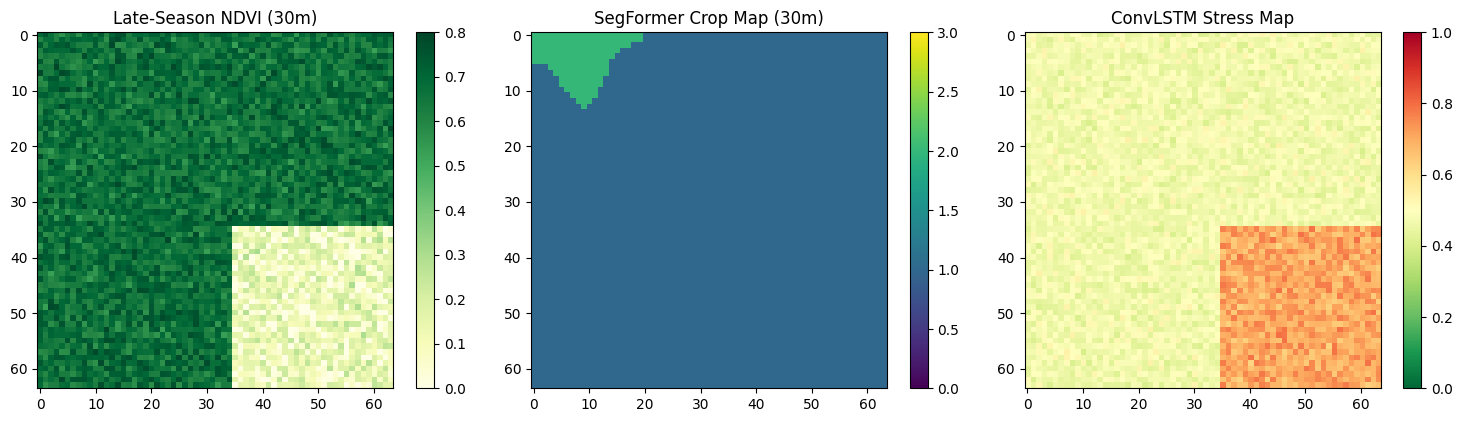

In [17]:
import sys
sys.path.append("cropshift_ai")

import numpy as np
import torch
import matplotlib.pyplot as plt

from config import DEFAULT_REGION
from data_pipeline import fetch_nasa_power_climate, load_real_hls_cube, compute_spectral_indices
from models import CropSegFormer, SeasonalStressConvLSTM, train_rotation_xgb_model, prepare_tensor_for_segformer
from recommendation_engine import evaluate_rotations

# 1. Fetch Climate Data for Hyderabad / Jamshoro, Sindh
lat, lon = DEFAULT_REGION["lat"], DEFAULT_REGION["lon"]
climate_df = fetch_nasa_power_climate(lat, lon)
print(f"Loaded {len(climate_df)} daily climate records for {DEFAULT_REGION['name']}")

# 2. Load HLS 30m Cube (uses cropshift_ai/data/hls/*.tif if present, else fallback cube)
red_ts, nir_ts, swir_ts, is_real = load_real_hls_cube("cropshift_ai/data/hls", lat=lat, lon=lon)
ndvi_ts, ndmi_ts = compute_spectral_indices(red_ts, nir_ts, swir_ts)
print(f"Imagery Mode: {'Real NASA HLS GeoTIFFs' if is_real else 'Simulated HLS Cube'} | Shape: {ndvi_ts.shape}")

# 3. Run CropSegFormer & SeasonalStressConvLSTM
device = "cuda" if torch.cuda.is_available() else "cpu"
segformer = CropSegFormer(num_classes=4, pretrained=False).to(device).eval()
convlstm = SeasonalStressConvLSTM(input_dim=2, hidden_dim=16).to(device).eval()

with torch.no_grad():
    seg_in = prepare_tensor_for_segformer(red_ts[-1], nir_ts[-1], swir_ts[-1]).to(device)
    seg_mask = torch.argmax(segformer(seg_in), dim=1).squeeze().cpu().numpy()

    seq_in = torch.tensor(np.stack([ndvi_ts, ndmi_ts], axis=1), dtype=torch.float32).unsqueeze(0).to(device)
    stress_prob = convlstm(seq_in).squeeze().cpu().numpy()

combined_stress = np.clip(0.5 * stress_prob + 0.5 * (1.0 - (ndmi_ts[-1] + 0.2)), 0, 1)
stressed_fraction = float((combined_stress > 0.55).mean())

# 4. Score Crop Rotations with XGBoost + Rule-Based Explainability
xgb_scorer = train_rotation_xgb_model()
priorities = {"water": 0.8, "soil": 0.7, "profit": 0.6}
recs_df = evaluate_rotations(xgb_scorer, climate_df, stressed_fraction, priorities)

display(recs_df[["Scenario", "Suitability Score", "Water Demand (mm)", "Soil N Impact", "Heat Resilience", "Est. Net Return (PKR/acre)"]])
print("\nTop Recommendation Explanation:")
print(recs_df.iloc[0]["Scenario"], "->", recs_df.iloc[0]["Advantages"])

# 5. Visualize NDVI, SegFormer Crop Segmentation & Stress Heatmap
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
im0 = axes[0].imshow(ndvi_ts[-1], cmap="YlGn", vmin=0, vmax=0.8)
axes[0].set_title("Late-Season NDVI (30m)")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(seg_mask, cmap="viridis", vmin=0, vmax=3)
axes[1].set_title("SegFormer Crop Map (30m)")
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(combined_stress, cmap="RdYlGn_r", vmin=0, vmax=1)
axes[2].set_title("ConvLSTM Stress Map")
plt.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()

## Launch the Full Interactive Streamlit Web App
Run the cell below to start `streamlit run cropshift_ai/app.py` in the background and expose a public URL.

In [40]:
from pyngrok import ngrok

# Replace with your actual authtoken from dashboard.ngrok.com
ngrok.set_auth_token("YOUR_NGROK_AUTHTOKEN_HERE")

# Start Streamlit in the background
!streamlit run app.py --server.port 8501 &>/content/streamlit.log &

# Expose port 8501 via Ngrok and print public URL
public_url = ngrok.connect(8501)
print("Open this secure URL in your browser:", public_url)

Open this secure URL in your browser: NgrokTunnel: "https://uplifted-henchman-irritate.ngrok-free.dev" -> "http://localhost:8501"
